# Interpreting what accessibility models have learned

In the previous notebook, we have trained a sequence to accessibility model for lymphoblastoid cells, now we are going to investigate <b>which sequence features are guiding the models predictions</b>.<br>
This allows us to identify motifs that might drive accessibility in the cell type that we have modelled, furthermore it serves as an additional sanity check, demonstrating that the model pays attention<br>
to "sensible" features that go beyond simple composition effects.

We will perform interpretability analyses on both a local as well as a global level.<br>
In <b>local interpretability</b> we look at individual sequences, e.g. specific putative enhancers that we are interested in, and ask which subparts of the sequence are especially revelant for accessibility of the element.<br>
In <b>global interpretability</b>, we ask which motifs and sequence features are most important for accessibility predictions globally throughout the genome.

In [1]:
import os
import sys
from pathlib import Path

def find_repo_root(marker="environment.yml"):
    """Walk up from the current working directory until a folder containing `marker` is found."""
    start = Path().resolve()
    for parent in [start, *start.parents]:
        if (parent / marker).exists():
            return parent
    raise RuntimeError(
        f"Could not find repo root: no '{marker}' found in {start} or any parent directory."
    )

repo_base_dir = str(find_repo_root())
os.environ["REPO_BASE_DIR"] = repo_base_dir  # so %%bash cells below can use $REPO_BASE_DIR

import pandas as pd

### Attributions with DeepLIFT

DeepLIFT feature attribution algorithm that has been specifically designed for (but not limited to) local interpretability of DNA sequence to function models.<br>
On a high abstraction level, it works by taking differences between models activations on the original input and models activations on shuffled versions of the sequence,<br>
then propagating these "deltas" backwards through the model until the input level, yielding feature importance profiles ("attributions") that tell us how important the<br>
presence of a specific nucleotide in a certain position is for explaining the "differences to background" for the given sequence input.<br>

We will use the DeepLIFT implementation from tangermem, for more details see<br>
https://tangermeme.readthedocs.io/en/latest/tutorials/Tutorial_A3_Deep_LIFT_SHAP.html

In [2]:
sys.path.append(f"{repo_base_dir}/src/01_model_architectures/")
from model_architectures import deepstarr_default_params, DeepSTARR

import torch

import pandas as pd
import numpy as np

from matplotlib import pyplot as plt

from tangermeme.deep_lift_shap import deep_lift_shap
from tangermeme.utils import one_hot_encode
from tangermeme.plot import plot_logo
from tangermeme.io import extract_loci

import pyfaidx

In [3]:
#Load trained accessibility model 

model_savedir = f"{repo_base_dir}/res/ENCODE_cellines/GM12878/saved_models/"
model_filepath = f"{model_savedir}/model.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"
model = DeepSTARR(**deepstarr_default_params).to(device)

model.load_state_dict(
    torch.load(model_filepath, weights_only=True, map_location = device)
)
_=model.eval()

#### Defining a region of interest 

Local interpretability can be useful for investigating predefined regions of interest, such as candidate regulatory elements.<br>
Below, an IGV genome browser screenshot of the accesibility landscape at the CD19 locus. <br>
This locus harbours an intergenic ATAC peaks distinct from the transcription start site of the gene, potentially representing distal cis regulatory element (CREs).<br>
To find out more about the regulatory mechanisms potentially governing the expression of the gene, we will fetch the reference sequences for a candidate regulatory elements,<br>
run DepLIFT on the sequence and see which important subpatterns are highlighted.


<img src="./img/CD19_locus.png" style="max-width: 1300px; width:100%; height: auto;">

In [19]:
#Fasta file containing the reference genome, for fetching sequence of the region of interest
genome_fasta = f'{repo_base_dir}/example_data/reference_genomes/hg38/hg38.fa'

#Define region of interest
peak_chrom, peak_start,peak_end = "chr16",28936536,28936858
peak_mid = peak_start+(peak_end-peak_start)//2
window_start, window_end = peak_mid - 500, peak_mid + 501 #1001 bp central part of the peak

#Retrieve sequence for region of interest
genome = pyfaidx.Fasta(genome_fasta)
peak_seq = genome[peak_chrom][window_start:window_end].seq.upper()

#Onehot encode sequence
peak_seq_onehot = one_hot_encode(peak_seq)
peak_seq_onehot = peak_seq_onehot.unsqueeze(0).to(torch.float32) #deeplift expects a batch dimension (even if only one sequence is persent) and float dtypes

In [20]:
peak_start-peak_end

-322

In [21]:
#Run deeplift feature attribution on the peak sequence
peak_attr = deep_lift_shap(model, peak_seq_onehot, device=device, random_state=0)

In [22]:
print("Shape of sequence tensor: ",peak_seq_onehot.shape)
print("Shape of attributions tensor: ",peak_attr.shape)
print("Attributions:")
peak_attr

Shape of sequence tensor:  torch.Size([1, 4, 1001])
Shape of attributions tensor:  torch.Size([1, 4, 1001])
Attributions:


tensor([[[ 0.0000,  0.0000,  0.0043,  ...,  0.0000,  0.0000, -0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000,  0.0000],
         [ 0.0000, -0.0034, -0.0000,  ..., -0.0009,  0.0000, -0.0000],
         [ 0.0000,  0.0000,  0.0000,  ...,  0.0000,  0.0000, -0.0000]]])

The attributions tensor has the same shape as the original sequence tensor and has zeros in the same places. The non zero entries indicate how strongly the present nucleotids contribute to "difference from background"

#### Visualising feature importance profiles

Having obtained the attribution profile, we can visualise it using the plot_logo function from tangermeme.<br>
Plotting attributions for the whole 1kb long sequence, we see that the central parts harbours some especially important subsequences,<br>
but also in the flanks we can find patterns that look like motif instances. Using start and end arguments of plot_logo, we can zoom in on these important subsequences to see if we can recognise familiar motifs.<br>

Text(0.5, 1.0, 'Attribution profile of peak of region of interest')

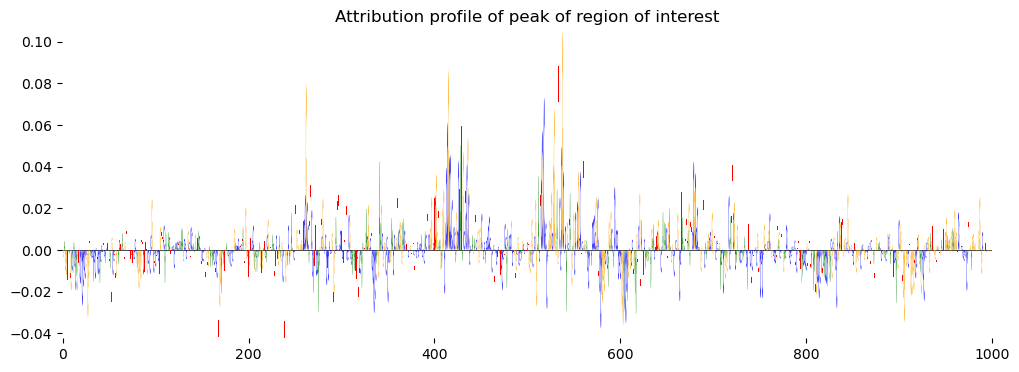

In [23]:
fig, ax = plt.subplots( figsize = (12,4))
plot_logo(peak_attr[0], ax=ax)
ax.set_title("Attribution profile of peak of region of interest")

Text(0.5, 1.0, 'Zoom position 500 - 600')

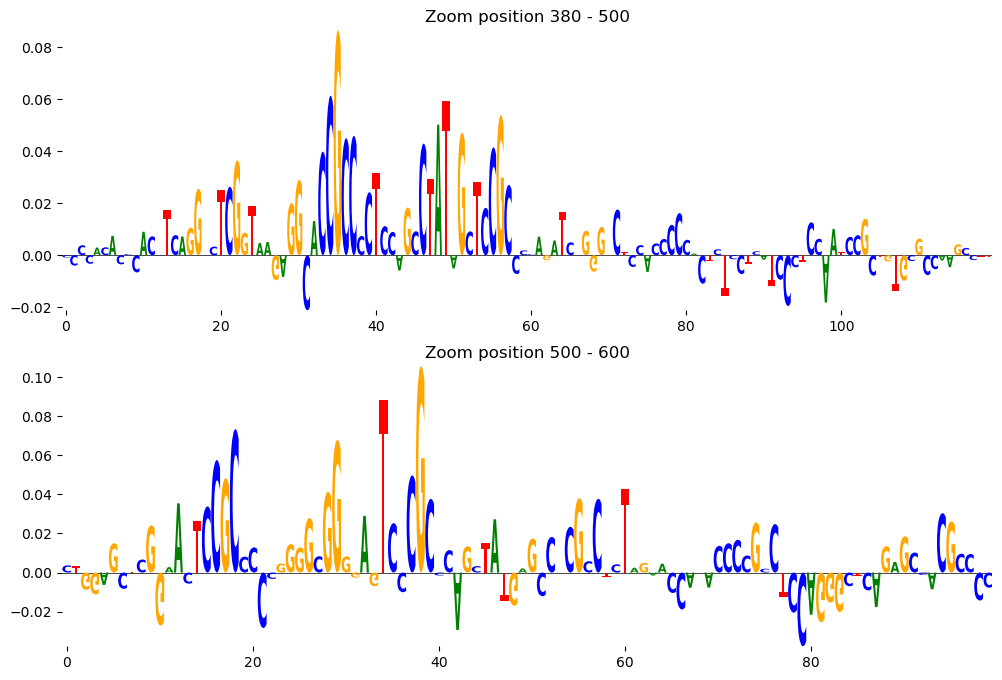

In [26]:
fig, ax = plt.subplots(nrows=2, figsize = (12,4*2))

plot_logo(peak_attr[0], ax=ax[0], start = 380, end = 500)
plot_logo(peak_attr[0], ax=ax[1], start = 500, end = 600)

ax[0].set_title("Zoom position 380 - 500")
ax[1].set_title("Zoom position 500 - 600")


Zooming in, we can see that one of the most importan subpart of the sequence, but its not easy to make sense of this. 
Therefore, in the next section we will annotate the important subsequences in a more systematic manner.

### Annotationg attribution seqlet with motif names

To systematically annotate important subsequences, we can try to match them to entries of a motif database like JASPAR.<br>
For this, we first need to call "seqlets" (=important subsequences, "peaks" in the attribution profile), then one can use the TOMTOM algorith to compare how similar the seqlet's sequence is to motif PWMs of the databse,<br> thereby identifying the best matching motif for each seqlet. We will use tangermeme's recursive_seqlets function for seqlet calling as well as the annotate_seqlets function (that uses tomtom under the hood) for seqlet annotation,<br> closely following the seqlet annotation recipe of tangermeme:<br>
https://tangermeme.readthedocs.io/en/latest/tutorials/Tutorial_A5_Annotations.html#Deriving-Annotations-from-Seqlets

In [31]:
from tangermeme.seqlet import recursive_seqlets
from tangermeme.annotate import annotate_seqlets
from tangermeme.io import read_meme

jaspar_motifs_file = f"{repo_base_dir}/example_data/motif_databases/JASPAR2026_CORE_non-redundant_pfms_meme.txt"

In [32]:
#Calling seqlets from attribution track
#(usually one needs to play around with additional_flanks and threshold to obtain a seqlet call that matches ones intuition)
seqlets = recursive_seqlets(peak_attr.sum(dim=1), additional_flanks=2, threshold=0.02)

#Load motifs from JASPAR vertebrate DB
motifs = read_meme(jaspar_motifs_file)
motif_names = list(motifs.keys())

#Annotating seqlets with motifs from database
motif_idxs, motif_pvalues = annotate_seqlets(peak_seq_onehot, seqlets, motifs)
seqlet_annotations = seqlets.copy()
seqlet_annotations['example_idx'] = [motif_names[idx] for idx in motif_idxs]

Text(0.5, 1.0, 'Annotated seqlets in region of interest')

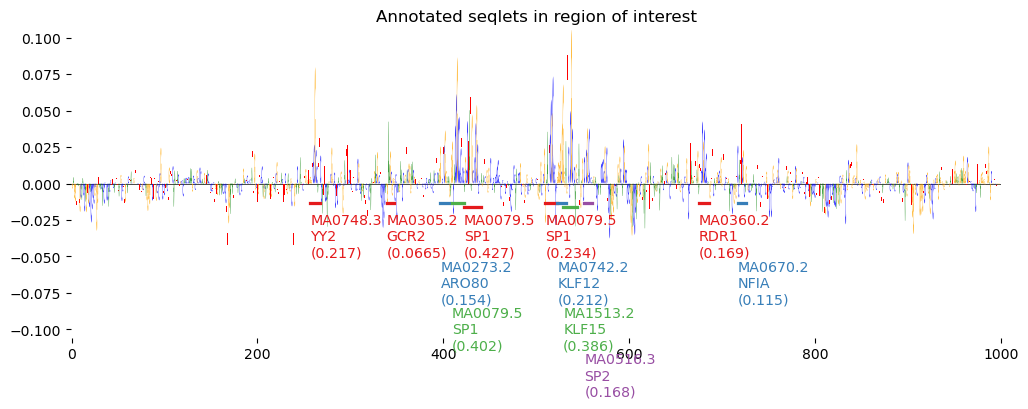

In [33]:
fig, ax = plt.subplots( figsize = (12,4))
plot_logo(peak_attr[0], ax=ax, annotations = seqlet_annotations, score_key="attribution")
ax.set_title("Annotated seqlets in region of interest")

Having annotated the seqlets, we find that we have multiple matches to SP1 and KLF motifs deemed important in this example sequence

### Global interpretability with tf-modisco

Besides investigating individual sequences, it is usually also interesting to find out which motifs and sequence features are globally most important for accessibility across a lot of different sequence examples.<br>
For answering this question, we can use tf-modisco, a tool for de novo motif discovery. <br>
Modisco takes as input a large amount of attribution profiles from different sequences, performs seqlet calling and then clusters seqlets using tomtom sililarity to obtain "prototypical" version of the different categories of important subsequences.<br>
Again, the discovered patterns are annotated with matches against a motif database (done by modisco under the hood).

We will be using the commandline tool from the modisco lite implementation:<br>
https://github.com/jmschrei/tfmodisco-lite

#### Regions for the modisco analysis

The first step in the modisco analysis is to choose the regions that we want to use for obtaining the attribution profiles that will serve as input to modisco.
In the following, we will pose the question of "Which motifs does the model belief are most important for a high accessibility in lymphoblastoid cells?"<br>
Therefore, start out with peak regions and we extract the sequences of these loci from the genome, run deeplift to obtain attribution profiles and save both attribution scores and onehot encoded sequences as compressed numpy .npz files that will serve as input for the modisco commandline tool.
Modisco runtime is strongly dependent on the number of sequences used, so for the sake of the demonstration we will subsample to only 1000 regions (we will still get meaningful results but in a real world application we might just take all the sequences)

In [34]:
#Load loci
peak_regions_file = f"{repo_base_dir}/res/ENCODE_cellines/GM12878/curated_regions/peak_regions_filtered.tsv"
peak_regions = pd.read_csv(peak_regions_file,sep="\t")


#Subsample loci for demonstration purpuses
n_sample = 1000
peak_regions_sample = peak_regions.sample(n_sample)

In [36]:
#Extract sequences for loci
regions_onehot = extract_loci(
    [peak_regions_sample],
    genome_fasta,
    in_signals=None,
    in_window=1001,
    out_window=1001,
    ignore=list('QWERYUIOPSDFHJKLZXVBNM'), 
    verbose=True
    )

Loading Loci: 100%|██████████| 1000/1000 [00:00<00:00, 3986.24it/s]


In [37]:
%%time
#Run feature attribution
regions_attr = deep_lift_shap(model, regions_onehot.to(torch.float32) , device=device, random_state=0)

/groups/stark/nikolaus.mandlburger/Projects/BPNet_hackathon/ext_src/tangermeme/tangermeme/deep_lift_shap.py:460: RuntimeWarning: Convergence deltas too high: tensor([4.7684e-07, 9.5367e-07, 2.3842e-07, 0.0000e+00, 0.0000e+00, 9.5367e-07,
        4.7684e-07, 4.7684e-07, 1.0133e-06, 2.3842e-07, 8.3447e-07, 4.7684e-07,
        0.0000e+00, 4.7684e-07, 9.5367e-07, 0.0000e+00, 0.0000e+00, 9.5367e-07,
        1.1065e-03, 1.4305e-06, 9.5367e-07, 0.0000e+00, 4.7684e-07, 0.0000e+00,
        9.5367e-07, 4.7684e-07, 7.1526e-07, 9.5367e-07, 5.9605e-07, 0.0000e+00,
        9.5367e-07, 5.9605e-08], device='cuda:0', grad_fn=<AbsBackward0>)
  warnings.warn("Convergence deltas too high: " +
/groups/stark/nikolaus.mandlburger/Projects/BPNet_hackathon/ext_src/tangermeme/tangermeme/deep_lift_shap.py:460: RuntimeWarning: Convergence deltas too high: tensor([0.0000e+00, 3.5763e-07, 4.7684e-07, 4.7684e-07, 0.0000e+00, 0.0000e+00,
        2.3842e-07, 9.5367e-07, 4.7684e-07, 0.0000e+00, 7.1526e-07, 7.7486e-07,


CPU times: user 49.4 s, sys: 24.9 s, total: 1min 14s
Wall time: 38.5 s


In [39]:
#Save attribution profiles and onehot encoded sequences

os.makedirs(f"{repo_base_dir}/res/ENCODE_cellines/GM12878/feature_attribution/", exist_ok=True)

np.savez_compressed(f"{repo_base_dir}/res/ENCODE_cellines/GM12878/feature_attribution/regions_onehot.npz", regions_onehot.numpy())
np.savez_compressed(f"{repo_base_dir}/res/ENCODE_cellines/GM12878/feature_attribution/regions_attr.npz", regions_attr.numpy())

#### Important note on storage space
Sequences and attribution profiles saved in this manner can take up a lot of storage space, one needs to be mindful of this when doing modisco analyses.<br>
Especially...
- Pay attention to array dtype, use np.int8 for sequences and np.float32 for attribution profiles 
- Use np.savez_compressed rather than np.savez
- Remove npz files when modisco analysis is finished

#### Running modisco

The following code cells execute bash code and run the modisco commandline tools for motif discovery and report generation.<br>
Normally, one would run this code from the command line or a bash script.
- SEQS and CONTRIBS variables specify the input npz files that we just generated.<br>
- MODISCO_H5 specifies the H5 file that modisco motif discovery will produce and which is in turn used by modisco report to perform database (JASPAR_VERT_FILE) matching and generation of the visual output.<br>
- ADD_TFNAME_SCRIPT is a helper script that adds motif names in addition to JASPAR IDs in the output table.<br>

In [40]:
%%bash

SEQS=$REPO_BASE_DIR/res/ENCODE_cellines/GM12878/feature_attribution/regions_onehot.npz
CONTRIBS=$REPO_BASE_DIR/res/ENCODE_cellines/GM12878/feature_attribution/regions_attr.npz
MODISCO_H5=$REPO_BASE_DIR/res/ENCODE_cellines/GM12878/feature_attribution/regions_modisco.h5

modisco motifs -s ${SEQS} -a ${CONTRIBS} -n 50000 -o $MODISCO_H5 

In [45]:
%%bash

MODISCO_H5=$REPO_BASE_DIR/res/ENCODE_cellines/GM12878/feature_attribution/regions_modisco.h5
MODISCO_OUTDIR=$REPO_BASE_DIR/res/ENCODE_cellines/GM12878/feature_attribution/regions_modisco/

JASPAR_VERT_FILE=$REPO_BASE_DIR/example_data/motif_databases/JASPAR2026_CORE_non-redundant_pfms_meme.txt
ADD_TFNAME_SCRIPT=$REPO_BASE_DIR/src/02_accessory_functions/add_tfname_to_modiscoreport.py

modisco report -i ${MODISCO_H5} -o ${MODISCO_OUTDIR} -m ${JASPAR_VERT_FILE} && $ADD_TFNAME_SCRIPT -r ${MODISCO_OUTDIR}motifs.html

      <td>MA0081.3 - SPIB</td>

      <td>MA2522.1 - ZNF683</td>

      <td>MA0080.7 - Spi1</td>

      <td>MA0517.2 - STAT1::STAT2</td>

      <td>MA0652.2 - IRF8</td>

      <td>MA0653.1 - IRF9</td>

      <td>MA0139.2 - CTCF</td>

      <td>MA1930.2 - CTCF</td>

      <td>MA1929.2 - CTCF</td>

      <td>MA1134.2 - FOS::JUNB</td>

      <td>MA0491.3 - JUND</td>

      <td>MA0655.1 - JDP2</td>

      <td>MA1989.2 - Bcl11B</td>

      <td>MA0002.3 - Runx1</td>

      <td>MA1971.2 - ZBED2</td>

      <td>MA1911.2 - Rel</td>

      <td>MA2213.1 - Dif</td>

      <td>MA0107.1 - RELA</td>

      <td>MA1989.2 - Bcl11B</td>

      <td>MA0002.3 - Runx1</td>

      <td>MA1768.2 - MYB30</td>



#### Modisco output

Modisco produces output tables like the one below, indicating which classes prototypical sequence patterns are driving accessibility predictions on a global scale.
On the left side one can find the de novo discovered patterns with the top 3 database matches for each pattern on the righthand side.<br>


<img src="./img/modisco_report_example.png" style="max-width: 1600px; width: 70%; height: auto;">

#### Modisco final remark

Whereas deeplift attribution benefits from GPU accelleration, modisco works on CPU only, therefore the two things should be submitted as seperate jobs to not waste GPU time.